In [1]:
# Build and Train a Feedforward Neural Network
# o Use PyTorch or TensorFlow to build an MLP.
# o Train on MNIST dataset.
# o Tune hidden layers and activation functions.
# o Report accuracy and loss curves.

In [2]:
# Load Libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

I0000 00:00:1794466634.248308    6216 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794466639.957013    6216 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794466650.469169    6216 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# Load and preprocess MNIST CSV
train = pd.read_csv("dataset/Handwritten/mnist_train.csv")
test = pd.read_csv("dataset/Handwritten/mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [4]:
# Build and Train the 2 MLP Model
histories = []
results = []

configs = [(1, 'relu'), (2, 'tanh')]

for layers, activation in configs:
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(784,)))

    for i in range(layers):
        model.add(tf.keras.layers.Dense(128, activation=activation))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    print("Hidden layers:", layers, "Activation:", activation)
    print("Test accuracy:", accuracy * 100, "%")

    histories.append(history)
    results.append(accuracy)

E0000 00:00:1794466673.421206    6216 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794466674.128534    6216 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9114 - loss: 0.3190 - val_accuracy: 0.9580 - val_loss: 0.1534
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9581 - loss: 0.1471 - val_accuracy: 0.9685 - val_loss: 0.1109
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9706 - loss: 0.1016 - val_accuracy: 0.9737 - val_loss: 0.0951
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9767 - loss: 0.0768 - val_accuracy: 0.9740 - val_loss: 0.0881
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9827 - loss: 0.0586 - val_accuracy: 0.9765 - val_loss: 0.0808
Hidden layers: 1 Activation: relu
Test accuracy: 97.76999950408936 %
Epoch 1/5


W0000 00:00:1794466751.005714    6216 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.9114 - loss: 0.3044 - val_accuracy: 0.9592 - val_loss: 0.1427
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9579 - loss: 0.1389 - val_accuracy: 0.9720 - val_loss: 0.0998
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9713 - loss: 0.0940 - val_accuracy: 0.9705 - val_loss: 0.0947
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9787 - loss: 0.0692 - val_accuracy: 0.9758 - val_loss: 0.0776
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9850 - loss: 0.0515 - val_accuracy: 0.9765 - val_loss: 0.0782
Hidden layers: 2 Activation: tanh
Test accuracy: 97.50000238418579 %


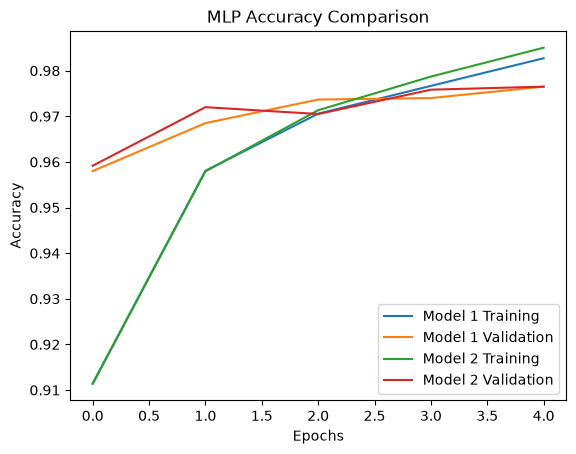

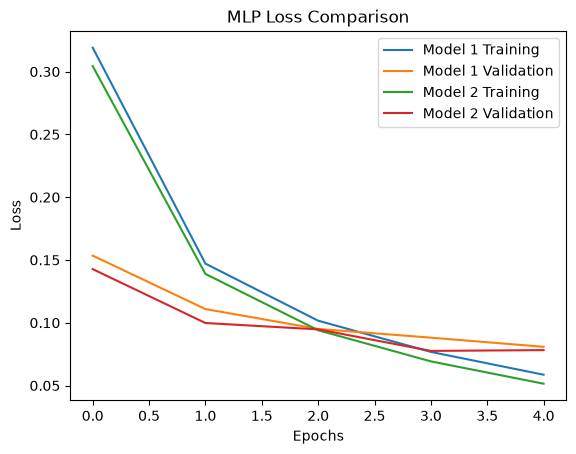

Model 1 Accuracy: 97.76999950408936 %
Model 2 Accuracy: 97.50000238418579 %
Best Model: Model 1


In [6]:
# Plot curves 
for i, h in enumerate(histories):
    plt.plot(h.history['accuracy'], label=f'Model {i+1} Training')
    plt.plot(h.history['val_accuracy'], label=f'Model {i+1} Validation')

plt.title("MLP Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

for i, h in enumerate(histories):
    plt.plot(h.history['loss'], label=f'Model {i+1} Training')
    plt.plot(h.history['val_loss'], label=f'Model {i+1} Validation')

plt.title("MLP Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Model 1 Accuracy:", results[0] * 100, "%")
print("Model 2 Accuracy:", results[1] * 100, "%")
print("Best Model:", "Model 1" if results[0] > results[1] else "Model 2")